### Importing Libraries

In [22]:
# Import the necessary libraries

import os
import json
import torch
import sklearn
import numpy as np
import pandas as pd
from tqdm import tqdm
import seaborn as sns
from pathlib import Path
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from wordcloud import WordCloud

from transformers import BatchEncoding
from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch
from category_encoders import BinaryEncoder
from sklearn.metrics import pairwise_distances
from transformers import BertTokenizer, BertModel
from sklearn.metrics import silhouette_score, calinski_harabasz_score, silhouette_samples

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import SpectralClustering
from sklearn.cluster import AffinityPropagation

### Loading & Saving the Dataset

In [2]:
class DataLoader:
    def __init__(self, data_path):
        self.data_path = data_path

    def load_data(self):
        data_list = []

        for file in os.listdir(self.data_path):
            if file.endswith('.json'):
                data = self._extract_data(os.path.join(self.data_path, file))
                if all(value != '' for value in data.values()):
                    data_list.append(data)

        return pd.DataFrame(data_list)

    def _extract_data(self, file_path):
        with open(file_path, 'r', encoding='utf-8') as file:
            data = json.load(file)

        protocol = data.get('protocolSection', {})
        identification = protocol.get('identificationModule', {})
        description = protocol.get('descriptionModule', {})
        conditions = protocol.get('conditionsModule', {})
        design = protocol.get('designModule', {})
        eligibility = protocol.get('eligibilityModule', {})

        primary_purpose = design.get('designInfo', {}).get('primaryPurpose', '')


        extracted_data = {
            "NCT ID": self._try_except(identification, 'nctId'),
            "Study Type": self._try_except(design, 'studyType'),
            "Standard Ages": self._try_except(eligibility, 'stdAges', join=True),
            "Conditions": self._try_except(conditions, 'conditions', join=True),
            "Eligibility Criteria": self._try_except(eligibility, 'eligibilityCriteria'),
            "Sex": self._try_except(eligibility, 'sex')
        }

        return extracted_data

    def _try_except(self, data_dict, field_name, join=False):
        try:
            value = data_dict.get(field_name, '')
            if join and isinstance(value, list):
                return ", ".join(value)
            return value
        except Exception as e:
            print(f"Error extracting {field_name}: {str(e)}")
            return ''

In [4]:
def extract_raw_data(input_dir=None, output_file=None):
    '''
    Extracts raw data from the json files and saves it to a csv file.

    Parameters:
    - input_dir (str): The directory containing the input JSON files.
    - output_file (str): The name of the CSV file to save the raw data.

    Returns:
    None
    '''
    if input_dir is None or output_file is None:
        raise ValueError("Both 'input_dir' and 'output_file' must be specified.")

    # Assuming DataLoader is a class that loads data from JSON files
    dataloader = DataLoader(input_dir)
    raw_data = dataloader.load_data()

    # Save raw data to CSV
    raw_data.to_csv(output_file, index=False)

    print(f"Raw data extracted to {output_file}")


In [5]:
input_dir = Path(r'.\data\ctg-studies.json')
output_file = Path(r'.\data\ctg-studies.csv')

extract_raw_data(input_dir=input_dir, output_file=output_file)

Raw data extracted to data\ctg-studies.csv


### Description of the Dataset

In [13]:
raw_data = pd.read_csv(r'.\data\ctg-studies.csv', encoding="utf8")
raw_data.isna().sum()

NCT ID                  0
Study Type              0
Standard Ages           0
Conditions              0
Eligibility Criteria    0
Sex                     0
dtype: int64

In [14]:
raw_data.describe()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
count,1266,1266,1266,1266,1266,1266
unique,1266,3,6,862,1254,3
top,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Multiple Myeloma,Inclusion Criteria:\r\n\r\n1. Age ≥18 years ol...,ALL
freq,1,1198,836,78,3,1239


In [15]:
raw_data.head()

,NCT ID,Study Type,Standard Ages,Conditions,Eligibility Criteria,Sex
0,NCT00019136,INTERVENTIONAL,"ADULT, OLDER_ADULT",Ovarian Cancer,DISEASE CHARACTERISTICS:\r\n\r\n* Histological...,FEMALE
1,NCT00085930,INTERVENTIONAL,"CHILD, ADULT",Neuroblastoma,Inclusion Criteria:\r\n\r\nHigh risk neuroblas...,ALL
2,NCT00881920,INTERVENTIONAL,"ADULT, OLDER_ADULT","Lymphoma, Myeloma, Leukemia",INCLUSION CRITERIA:\r\n\r\nBLOOD PROCUREMENT:\...,ALL
3,NCT00902044,INTERVENTIONAL,"CHILD, ADULT, OLDER_ADULT",Sarcoma,INCLUSION CRITERIA:\r\n\r\nProcurement Eligibi...,ALL
4,NCT00924326,INTERVENTIONAL,"ADULT, OLDER_ADULT","Primary Mediastinal B-cell Lymphoma, Diffuse, ...",* INCLUSION CRITERIA:\r\n\r\n 1. Patient must...,ALL


In [16]:
raw_data['Study Type'].value_counts()

INTERVENTIONAL     1198
OBSERVATIONAL        63
EXPANDED_ACCESS       5
Name: Study Type, dtype: int64

In [17]:
raw_data['Standard Ages'].value_counts()

ADULT, OLDER_ADULT           836
CHILD, ADULT, OLDER_ADULT    316
CHILD, ADULT                  97
ADULT                          9
CHILD                          7
OLDER_ADULT                    1
Name: Standard Ages, dtype: int64

In [18]:
raw_data['Sex'].value_counts()

ALL       1239
FEMALE      15
MALE        12
Name: Sex, dtype: int64

### Exploratory Data Analysis

[nltk_data] Downloading package punkt to C:\Users\Prerit
[nltk_data]     Gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Prerit
[nltk_data]     Gupta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


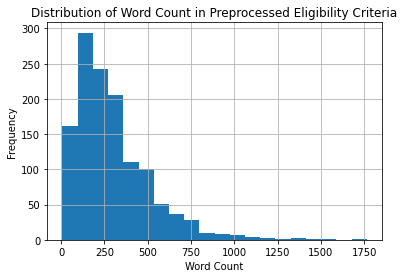

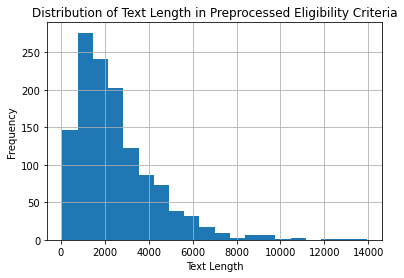

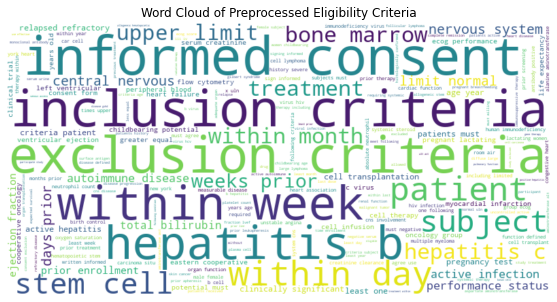

In [23]:
import pandas as pd
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import nltk
import string
nltk.download('punkt')
nltk.download('stopwords')

# Assuming 'raw_data' is your existing DataFrame with eligibility criteria text
# Make sure 'eligibility_criteria' is the column name containing the text

# Tokenization, lowercase, remove stopwords, and punctuations
stop_words = set(stopwords.words("english"))
punctuation = set(string.punctuation)

def preprocess_text(text):
    tokens = word_tokenize(text)
    tokens = [word.lower() for word in tokens if word.isalpha()]  # Remove non-alphabetic tokens
    tokens = [word for word in tokens if word not in stop_words]   # Remove stopwords
    tokens = [word for word in tokens if word not in punctuation]  # Remove punctuation
    return ' '.join(tokens)

# Preprocess eligibility criteria and add to DataFrame
raw_data['preprocessed_eligibility'] = raw_data['Eligibility Criteria'].apply(preprocess_text)

# Exploratory Data Analysis (EDA)
# You can perform various analyses depending on your goals. Here's a simple example:

# Word count distribution
raw_data['word_count'] = raw_data['preprocessed_eligibility'].apply(lambda x: len(x.split()))
raw_data['word_count'].hist(bins=20)
plt.title('Distribution of Word Count in Preprocessed Eligibility Criteria')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.savefig('./figures/word_count_distribution.png')
plt.show()

raw_data['text_length'] = raw_data['preprocessed_eligibility'].apply(len)
raw_data['text_length'].hist(bins=20)
plt.title('Distribution of Text Length in Preprocessed Eligibility Criteria')
plt.xlabel('Text Length')
plt.ylabel('Frequency')
plt.savefig('./figures/text_length_distribution.png')
plt.show()

# Top frequent words
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = ' '.join(raw_data['preprocessed_eligibility'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Preprocessed Eligibility Criteria')
plt.savefig('./figures/word_cloud.png')
plt.show()


In [24]:

count_long_texts = len(raw_data[raw_data['preprocessed_eligibility'].apply(len) > 5000])

print(f"Number of trials with preprocessed text length greater than 8000: {count_long_texts}")

Number of trials with preprocessed text length greater than 8000: 116


### Feature Extraction

In [25]:
raw_data = raw_data[raw_data['preprocessed_eligibility'].apply(len) <= 5000]

In [ ]:
bert_model = BertModel.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")
tokenizer = BertTokenizer.from_pretrained("bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16")
hf_model = "bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"
def calculate_optimal_chunk_size(max_token_limit, average_text_length, safety_margin=10):
    # Calculate an estimated chunk size with a safety margin
    optimal_chunk_size = (max_token_limit - safety_margin) // 2  # Assuming even distribution of tokens

    # Adjust the chunk size based on the average text length
    if optimal_chunk_size > average_text_length:
        optimal_chunk_size = min(optimal_chunk_size, average_text_length)

    return optimal_chunk_size

# Example usage
max_token_limit = 512  # Adjust based on your BERT model
average_text_length = math.ceil(raw_data['text_length'].mean()) # Calculate based on your preprocessed text

optimal_chunk_size = calculate_optimal_chunk_size(max_token_limit, average_text_length)
print(f"Optimal Chunk Size: {optimal_chunk_size}")

In [ ]:
class BERTFeatureExtractor:
    def __init__(self, hf_model="bionlp/bluebert_pubmed_mimic_uncased_L-24_H-1024_A-16"):
        self.bert_model = BertModel.from_pretrained(hf_model)
        self.tokenizer = BertTokenizer.from_pretrained(hf_model)
        self.encoder = BinaryEncoder()


    def extract_features(self, text):
        inputs = self.tokenizer.encode_plus(text, return_tensors='pt')
        input_ids = inputs['input_ids']
        attention_masks = inputs['attention_mask']

        input_chunks = [
            {
                'input_ids': input_ids[:, i:i + 512].clone().detach(),
                'attention_mask': attention_masks[:, i:i + 512].clone().detach()
            } for i in range(0, input_ids.size(1), 500)
        ]

        input_chunks = [BatchEncoding(inp) for inp in input_chunks]

        outputs = []

        for inp in input_chunks:
            output = self.bert_model(**inp)  # Use **inp to pass dictionary as keyword arguments
            embeddings = output.last_hidden_state.mean(dim=1).squeeze().detach()
            outputs.append(embeddings)

        return torch.cat(outputs, dim=0).numpy()

    def pad(self, vectors):
        max_length = max(len(vector) for vector in vectors)
        padded_vectors = [np.concatenate([vector, np.zeros(max_length - len(vector))]) for vector in vectors]
        return padded_vectors

    def extract_features_from_raw_data(self, raw_data):

        categorical_features = self.encoder.fit_transform(raw_data[['Study Type', 'Sex', 'Standard Ages']])
        text_features = []

        for text in tqdm(raw_data['Eligibility Criteria']):
            extracted_features = self.extract_features(text)
            text_features.append(extracted_features)

        text_features = self.pad(text_features)

        return pd.concat([categorical_features, pd.DataFrame(text_features)], axis=1)

# Example usage
bert_feature_extractor = BERTFeatureExtractor()
features = bert_feature_extractor.extract_features_from_raw_data(raw_data)


## Clustering Methods

### K-Means Clustering

In [ ]:
# Feature Matrix
X_feature = feature_matrix.drop(columns=['NCT ID'])

# PCA
pca_feature = PCA(n_components=256)
X_pca_feature = pca_feature.fit_transform(X_feature)
print(f"Explained variance ratio - Features: {sum(pca_feature.explained_variance_ratio_)}")

#### Elbow Method - Optimal Clusters

In [ ]:
objective_function = []

for i in range(1, 15):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=1)
    kmeans.fit(X_pca_feature)
    objective_function.append(kmeans.inertia_)

plt.plot(range(1, 15), objective_function)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('Objective Function')
plt.show()

#### Plotting the Clusters

In [ ]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=1)
kmeans.fit(X_pca_feature)
labels = kmeans.labels_

plot_silhouette_samples(X_pca_feature, labels)

### Agglomerative Clustering

#### Plotting Dendogram

In [ ]:
def plot_dendograms(dataset=None):
    linkages = ['single', 'complete', 'average']
    metrics = ['euclidean', 'cityblock', 'cosine']

    for linkage in linkages:
        print(f"Linkage: {linkage}")
        for metric in metrics:
            print(f"Metric: {metric}")
            cluster_visualising=sch.dendrogram(sch.linkage(X_pca_biobert,method=linkage, metric=metric))
            unique_colors = np.unique(cluster_visualising['color_list'])
            print(f"Optimal number of clusters: {len(unique_colors)-1}")
            plt.title('Dendrogram')
            plt.xlabel('Trials')
            plt.ylabel('Euclidean distances')
            plt.show()
        print()

plot_dendograms(X_pca_feature)

#### Plotting the Clusters

In [ ]:
agglomerative_clustering = AgglomerativeClustering(n_clusters=2, metric='euclidean', linkage='ward')
labels = agglomerative_clustering.fit_predict(X_pca_feature)

plot_silhouette_samples(X_pca_feature, labels)
print(labels)

### DBSCAN Clustering

#### Finding Optimal ep ( Epsilon ) Value

In [ ]:
feature_matrix = feature_matrix.sort_values(by=['NCT ID'])

dists = []
for i in range(len(feature_matrix) - 1):
    dist = np.linalg.norm(feature_matrix.iloc[i, 1:] - feature_matrix.iloc[i + 1, 1:])
    dists.append(dist)

df = pd.DataFrame({'index': range(len(dists)), 'distance': dists})
df = df.sort_values(by=['distance'], ascending=True)
print(df.head())

plt.scatter(df['index'], df['distance'])
plt.title('All Distances')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.show()

df2 = df[(df["distance"] < 15) & (df["distance"] > 10)]
df2 = df2.sort_values(by=['distance'])

plt.scatter(df2['index'], df2['distance'])
plt.title('Distances between 10 and 15')
plt.xlabel('Index')
plt.ylabel('Distance')
plt.show()

#### Finding Optimal min_samples Value

In [ ]:
from sklearn.cluster import DBSCAN

X_feature = feature_matrix.drop(columns=['NCT ID'])

# PCA
pca_feature = PCA(n_components=256)
X_pca_feature = pca_feature.fit_transform(X_feature)

range_eps= np.arange(10,15)
min_samples = np.arange(100,260)
max_silhouette_avg = 0
best_eps = 0
best_min_samples = 0
for i in range_eps:
    for j in min_samples:
        db=DBSCAN(eps=i,min_samples=j, metric='euclidean').fit(X_pca_feature)
        core_samples_mask=np.zeros_like(db.labels_,dtype=bool)
        core_samples_mask[db.core_sample_indices_]=True
        labels=db.labels_
        silhouette_avg=silhouette_score(X_pca_feature,labels)

        if silhouette_avg > max_silhouette_avg:
            max_silhouette_avg = silhouette_avg
            best_eps = i
            best_min_samples = j
print(f"Best eps: {best_eps}")
print(f"Best min_samples: {best_min_samples}")
print(f"Best silhouette score: {max_silhouette_avg}")

#### Plotting Clusters

In [ ]:
db=DBSCAN(eps=13,min_samples=186, metric='euclidean').fit(X_pca_feature)
core_samples_mask=np.zeros_like(db.labels_,dtype=bool)
core_samples_mask[db.core_sample_indices_]=True
labels=db.labels_
silhouette_avg=silhouette_score(X_pca_feature,labels)
plot_silhouette_samples(X_pca_feature, labels)